---
title: "Self-study Lab 7: Classification, from Linear to Logistic Regression"
subtitle: "Machine Learning, Lecture 4: Logistic regression"
author: "Khiem Nguyen"
format:
  html:
    toc: true
    toc-depth: 3
    embed-resources: true
    code-overflow: wrap
    fig-align: center
jupyter: python3
---

## Objectives

In this self-study lab you will

- describe a binary classification problem and plot its data;
- see why linear regression is a very bad approach to classification;
- implement the sigmoid function and the logistic regression model;
- read the output of the model as a probability;
- turn probabilities into predictions with a threshold, and compute the decision boundary.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

## Classification problems

Examples of classification problems are: is this email spam? Is this transaction fraudulent? Is this tumour malignant? The target $y$ takes only two values, so these are **binary classification** problems. We encode the two classes as numbers:

- $y = 0$, the **negative** class: "no", "false", e.g. a benign tumour;
- $y = 1$, the **positive** class: "yes", "true", e.g. a malignant tumour.

"Negative" and "positive" do not mean bad and good: the positive class is the **presence** of the property we are looking for.

### Data with one feature

We use the tumour data from the lecture: the tumour size $x$ (in cm) of nine patients with their diagnosis $y$.

In [2]:
x_train = np.array([0.6, 1.0, 1.4, 1.8, 2.2, 3.0, 3.4, 3.8, 4.2])
y_train = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1])

# Boolean masks: pos[i] is True if y_train[i] == 1, neg[i] is True if y_train[i] == 0
pos = (y_train == 1)
neg = (y_train == 0)
print(f"pos = {pos}")
print(f"malignant tumour sizes: {x_train[pos]}")

pos = [False False False False False  True  True  True  True]
malignant tumour sizes: [3.  3.4 3.8 4.2]


Indexing an array with a Boolean mask, as in `x_train[pos]`, keeps exactly the entries where the mask is `True`. Classification plots usually show the classes with different symbols: here `x` for $y = 1$ and `o` for $y = 0$.

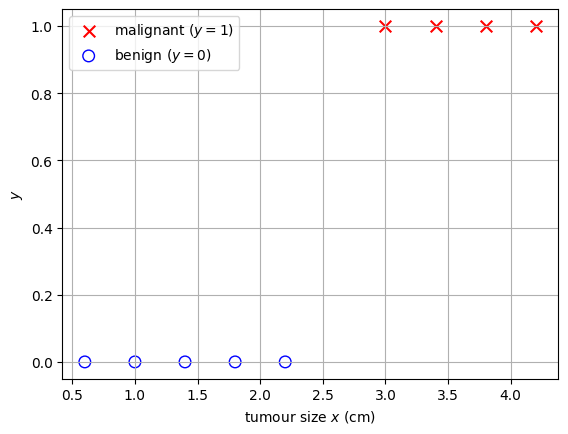

In [3]:
def plot_classes(x, y, ax=None):
    """Plot 1D classification data: red crosses for y = 1, blue circles for y = 0."""
    ax = plt.gca() if ax is None else ax
    ax.scatter(x[y == 1], y[y == 1], marker='x', c='r', s=70, label='malignant ($y = 1$)')
    ax.scatter(x[y == 0], y[y == 0], marker='o', facecolor='none', edgecolor='b', s=70, label='benign ($y = 0$)')
    ax.set_xlabel('tumour size $x$ (cm)')
    ax.set_ylabel('$y$')
    ax.grid(True)

plot_classes(x_train, y_train)
plt.legend()
plt.show()

With two features $x_1, x_2$, we plot the examples in the $(x_1, x_2)$-plane instead and show the class only by the symbol (Lab 8).

## The linear regression approach

In Lectures 2 and 3 we fitted straight lines. Let us try this here: fit $f_{w,b}(x) = wx + b$ by least squares and predict $\hat y = 1$ when $f_{w,b}(x) \ge 0.5$. The **decision boundary** is the point where the line crosses $0.5$, i.e. $x = (0.5 - b)/w$. We put the whole procedure into a function, because we will use it twice.

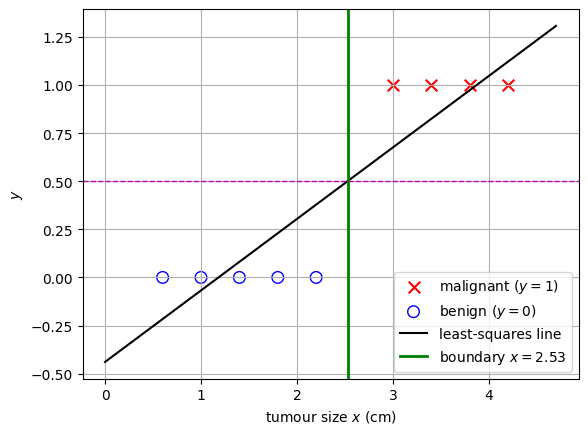

In [4]:
def classify_with_linear_regression(x, y):
    """Fit a least-squares line, plot it with its 0.5 decision boundary, return the boundary."""
    w, b = np.polyfit(x, y, deg=1)                 # note the order: slope first, then intercept
    boundary = (0.5 - b) / w
    xs = np.array([0, x.max() + 0.5])
    plot_classes(x, y)
    plt.plot(xs, w * xs + b, 'k-', label='least-squares line')
    plt.axhline(0.5, color='m', ls='--', lw=1)
    plt.axvline(boundary, color='g', lw=2, label=f'boundary $x = {boundary:.2f}$')
    plt.legend(loc='lower right')
    plt.show()
    return boundary

boundary_9 = classify_with_linear_regression(x_train, y_train)

Everything to the left of the green line is predicted benign, everything to the right malignant: the prediction is perfect. Now we add two very large tumours. They are obviously malignant, so they should change nothing.

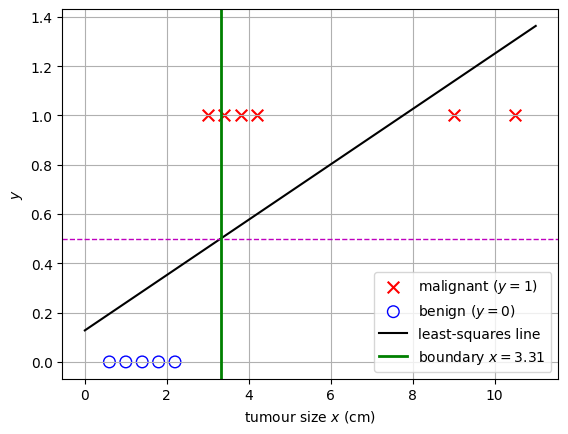

boundary moved from 2.53 to 3.31 cm
malignant tumours now predicted benign: [3.] cm


In [5]:
x_all = np.concatenate([x_train, [9.0, 10.5]])
y_all = np.concatenate([y_train, [1, 1]])
boundary_11 = classify_with_linear_regression(x_all, y_all)
print(f"boundary moved from {boundary_9:.2f} to {boundary_11:.2f} cm")
print(f"malignant tumours now predicted benign: {x_all[(y_all == 1) & (x_all < boundary_11)]} cm")

Two easy examples, far from the boundary, tilt the line and move the boundary from $2.53$ to $3.31$ cm, so a malignant tumour of $3.0$ cm is now predicted benign. Linear regression has two problems for classification:

- **easy examples move the boundary**: points far from the boundary pull the line;
- **the output is not a probability**: the line takes values below $0$ and above $1$.

## Logistic regression

### The sigmoid function

We want a model whose output always lies between $0$ and $1$. The **sigmoid** (or **logistic**) function squashes any real number into the interval $(0, 1)$:
$$
g(z) = \frac{1}{1 + e^{-z}} .
$$

g(z) = [0.    0.119 0.5   0.881 1.   ]
g(10) = 0.99995
g(-z) = 1 - g(z): True


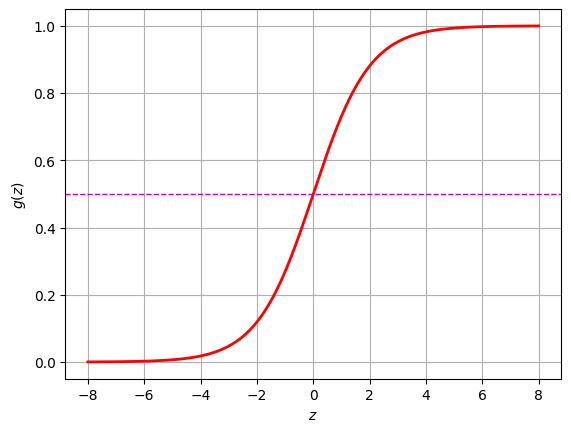

In [6]:
def sigmoid(z):
    """Sigmoid function g(z) = 1 / (1 + exp(-z)), element by element."""
    return 1.0 / (1.0 + np.exp(-z))

z = np.array([-10.0, -2.0, 0.0, 2.0, 10.0])
print(f"g(z) = {sigmoid(z)}")
print(f"g(10) = {sigmoid(10.0):.5f}")
print(f"g(-z) = 1 - g(z): {np.allclose(sigmoid(-z), 1 - sigmoid(z))}")

z_plot = np.linspace(-8, 8, 300)
plt.plot(z_plot, sigmoid(z_plot), 'r-', lw=2)
plt.axhline(0.5, color='m', ls='--', lw=1)
plt.xlabel('$z$')
plt.ylabel('$g(z)$')
plt.grid(True)
plt.show()

As in the lecture: $0 < g(z) < 1$ for every $z$, $g(0) = 0.5$, $g(z) \to 1$ as $z \to \infty$ (e.g. $g(10) \approx 0.99995$), $g(z) \to 0$ as $z \to -\infty$, and $g(-z) = 1 - g(z)$.

::: {.callout-tip title="Very negative inputs"}
For $z$ around $-1000$, `np.exp(-z)` overflows to infinity. NumPy then prints a `RuntimeWarning`, although the result $g(z) = 0$ is correct. `scipy.special.expit` computes the sigmoid without this warning.
:::

### The model

Logistic regression feeds the linear model of Lectures 2 and 3 into the sigmoid:
$$
f_{\mathbf w,b}(\mathbf x) = g(\underbrace{\mathbf w\cdot\mathbf x + b}_{z}) = \frac{1}{1 + e^{-(\mathbf w\cdot\mathbf x + b)}} .
$$
Despite its name, logistic regression is a **classification** algorithm. We fit it to the eleven patients, including the two large tumours, with scikit-learn's `LogisticRegression` (Labs 8 and 10 show how the parameters are found). Like `LinearRegression`, it expects a 2D array of features.

w = 1.435, b = -3.772, decision boundary at x = 2.63 cm


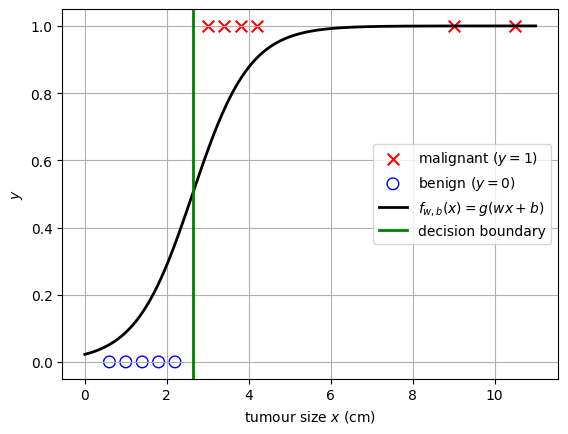

In [7]:
model = LogisticRegression()
model.fit(x_all.reshape(-1, 1), y_all)
w, b = model.coef_[0, 0], model.intercept_[0]       # coef_ has shape (1, n)
print(f"w = {w:.3f}, b = {b:.3f}, decision boundary at x = {-b / w:.2f} cm")

x_plot = np.linspace(0, 11, 300)
plot_classes(x_all, y_all)
plt.plot(x_plot, sigmoid(w * x_plot + b), 'k-', lw=2, label='$f_{w,b}(x) = g(wx + b)$')
plt.axvline(-b / w, color='g', lw=2, label='decision boundary')
plt.legend(loc='center right')
plt.show()

We get the lecture's values $w \approx 1.44$ and $b \approx -3.77$. The sigmoid saturates at $1$ for the large tumours, so they hardly affect the fit, and the boundary at $2.63$ cm lies between the two classes.

::: {.callout-note title="Why scikit-learn's default settings?"}
These data are **perfectly separable**. Then making the sigmoid steeper always fits the data a little better, and without any restriction the weights grow without bound (Lab 10 studies this). By default, `LogisticRegression` applies **regularisation**, which keeps the weights finite (Lecture 5).
:::

### The output is a probability

The output is read as $f_{\mathbf w,b}(\mathbf x) = P(y = 1 \mid \mathbf x;\ \mathbf w, b)$, the probability that $y = 1$ given the input $\mathbf x$. The probability of the other class is $P(y = 0 \mid \mathbf x) = 1 - f_{\mathbf w,b}(\mathbf x)$. `predict_proba` returns both, one column per class:

In [8]:
x_new = 3.2
print(f"our formula:   f = {sigmoid(w * x_new + b):.3f}")
print(f"predict_proba: [P(y=0), P(y=1)] = {model.predict_proba([[x_new]])[0]}")

our formula:   f = 0.694
predict_proba: [P(y=0), P(y=1)] = [0.306 0.694]


A tumour of $3.2$ cm has a $69\%$ chance (the lecture rounds to $70\%$) of being malignant and a $31\%$ chance of being benign.

**Log-odds (optional).** Solving $f = g(z)$ for $z$ gives $z = \mathbf w\cdot\mathbf x + b = \log\frac{f}{1 - f}$, the logarithm of the **odds** $f/(1 - f)$. Increasing $x$ by $1$ cm adds $w$ to the log-odds, i.e. multiplies the odds by $e^{w} \approx 4.2$.

## From probabilities to predictions

### The threshold and the decision boundary

To predict a class, we compare the probability with a **threshold** $\tau$, usually $\tau = 0.5$:
$$
\hat y = \begin{cases} 1 & \text{if } f_{\mathbf w,b}(\mathbf x) \ge \tau,\\ 0 & \text{otherwise.}\end{cases}
$$
Since $g(z) \ge 0.5$ exactly when $z \ge 0$, for $\tau = 0.5$ we get $\hat y = 1 \iff \mathbf w\cdot\mathbf x + b \ge 0$, and the **decision boundary** is $\mathbf w\cdot\mathbf x + b = 0$. For a general threshold, the boundary is where $f = \tau$:
$$
\frac{1}{1 + e^{-z}} = \tau \iff z = \log\frac{\tau}{1 - \tau},
\qquad\text{so in 1D}\qquad
x_\tau = \frac{1}{w}\left(\log\frac{\tau}{1 - \tau} - b\right).
$$

### Real data: the breast-cancer data set

We now use the Wisconsin breast-cancer data from the lecture: $569$ tumours, with the mean radius of the cell nuclei as the single feature $x$. scikit-learn codes **malignant as 0**, so we flip the labels to make malignant the positive class.

In [9]:
cancer = load_breast_cancer()
radius = cancer.data[:, list(cancer.feature_names).index('mean radius')]
y_cancer = 1 - cancer.target                          # 1 = malignant, 0 = benign
print(f"{len(y_cancer)} tumours: {y_cancer.sum()} malignant, {(1 - y_cancer).sum()} benign")

# A very large C switches the regularisation off (Lab 8); max_iter gives the solver enough steps
radius_model = LogisticRegression(C=1e10, max_iter=1000).fit(radius.reshape(-1, 1), y_cancer)
w_r, b_r = radius_model.coef_[0, 0], radius_model.intercept_[0]
print(f"w = {w_r:.3f}, b = {b_r:.2f}, decision boundary at x = {-b_r / w_r:.2f}")

569 tumours: 212 malignant, 357 benign
w = 1.034, b = -15.25, decision boundary at x = 14.75


With one feature the decision boundary is a single point, $x = -b/w = 14.75$. The plot shows the boundaries for three thresholds.

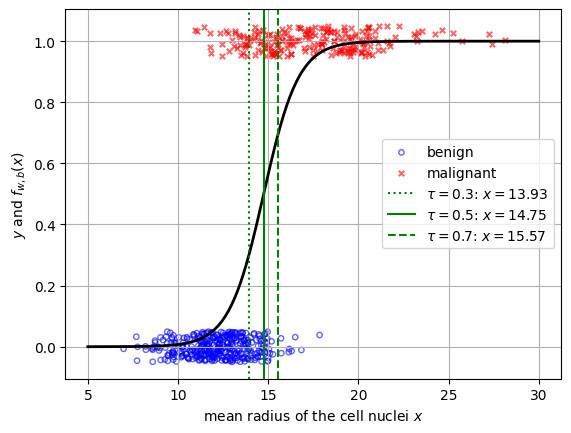

In [10]:
jitter = np.random.default_rng(1).uniform(-0.05, 0.05, len(y_cancer))   # only to spread the points
x_plot = np.linspace(5, 30, 300)
plt.scatter(radius[y_cancer == 0], jitter[y_cancer == 0], marker='o', facecolor='none',
            edgecolor='b', s=15, alpha=0.6, label='benign')
plt.scatter(radius[y_cancer == 1], 1 + jitter[y_cancer == 1], marker='x', c='r', s=15,
            alpha=0.6, label='malignant')
plt.plot(x_plot, sigmoid(w_r * x_plot + b_r), 'k-', lw=2)
for tau, style in [(0.3, ':'), (0.5, '-'), (0.7, '--')]:
    x_tau = (np.log(tau / (1 - tau)) - b_r) / w_r
    plt.axvline(x_tau, color='g', ls=style, label=f'$\\tau = {tau}$: $x = {x_tau:.2f}$')
plt.xlabel('mean radius of the cell nuclei $x$')
plt.ylabel('$y$ and $f_{w,b}(x)$')
plt.legend(loc='center right')
plt.grid(True)
plt.show()

As in the lecture, $\tau = 0.3, 0.5, 0.7$ give boundaries at about $13.9$, $14.75$ and $15.6$. A **higher** threshold predicts "malignant" only when the model is more certain: fewer false alarms, but more missed tumours. A **lower** threshold catches more malignant tumours at the cost of more false alarms, which is often preferred in medical screening.

The choice of $\tau$ depends on the application, i.e. on the cost of each kind of mistake; $\tau = 0.5$ is only the default. Lab 8 counts both kinds of mistake on a test set.

## Challenges

1. A model gives $f_{\mathbf w,b}(\mathbf x) = 0.2$ for a tumour. What is the probability that it is benign? What is $\hat y$ for $\tau = 0.5$?
2. Show that $g(-z) = 1 - g(z)$. (*Hint:* multiply the numerator and the denominator of $g(-z)$ by $e^{z}$.)
3. For the radius model, which threshold $\tau$ puts the decision boundary at a mean radius of exactly $14$?
4. Repeat the linear-regression experiment with a single extra tumour of $21$ cm instead of the two large ones. How far does the boundary move?

## Summary

- Binary classification: $y \in \{0, 1\}$, with $y = 1$ the class we are looking for.
- Linear regression is a very bad classifier: easy examples move its boundary, and its output is not a probability.
- Logistic regression: $f_{\mathbf w,b}(\mathbf x) = g(\mathbf w\cdot\mathbf x + b)$ with the sigmoid $g(z) = 1/(1 + e^{-z})$; the output is $P(y = 1 \mid \mathbf x)$.
- Predict $\hat y = 1$ when $f \ge \tau$; for $\tau = 0.5$ the decision boundary is $\mathbf w\cdot\mathbf x + b = 0$. Changing $\tau$ moves the boundary.

**Next (Lab 8):** several features, and how $\mathbf w$ and $b$ are found by gradient descent.